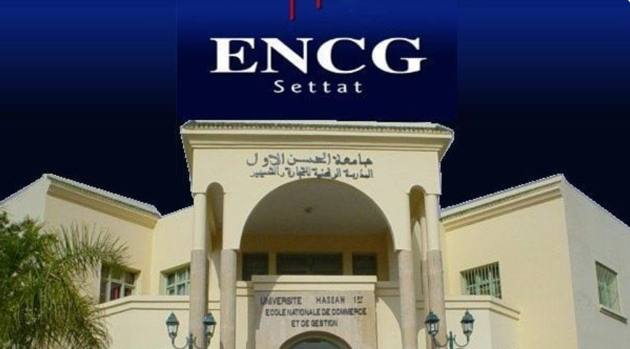

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CIXX est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** [ABAAKIL ASMA] · **Code Apogée :** [25008036] · **Groupe :** [CI]  
**Sujet :** CI[12] — [Exportations agroalimentaires] · **Date :** [19/11/2026]  
**Dépôt :**https://github.com/ABAAKIL5/25008036_ABAAKILASMA_CI.git

## 0. Configuration et reproductibilité
Installer au besoin les dépendances, noter leurs versions, fixer une graine. **Exécutez la cellule ci-dessous avant les autres.**

In [2]:
import sys, platform, pathlib, importlib.metadata
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 10})
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version)
print("Renseignez source, licence et version des données dans la section 2.")

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
Renseignez source, licence et version des données dans la section 2.


## 1. Sujet et problématique

**Sujet :** CI12 — Exportations agroalimentaires (prévoir tomates, agrumes et autres produits)

**Intérêt économique :**
Le secteur agroalimentaire est l'un des piliers des exportations marocaines. D'après UN Comtrade, les tomates fraîches (HS 0702) et les agrumes (HS 0805) représentent à eux seuls plus de 1,9 milliard USD d'exportations en 2025. Anticiper ces flux aide les exportateurs à planifier la production, le transport et la logistique frigorifique. Cela aide aussi les pouvoirs publics à orienter les accords commerciaux et les politiques d'appui, et les opérateurs à gérer le risque de volume et de change. Les produits suivent des trajectoires très différentes : les tomates, les dattes et avocats sont en forte croissance, alors que les agrumes restent plutôt stables. Un modèle unique capable de prévoir ces dynamiques est donc utile pour la décision commerciale.

**Problématique précise :**
Un modèle de régression (Ridge, comparé à Random Forest) appliqué à un panel annuel de six produits agricoles marocains (HS 0701, 0702, 0703, 0804, 0805, 0806), construit avec des variables retardées, prévoit-il la valeur des exportations vers le monde (2015–2025) mieux qu'une référence naïve de persistance (valeur de l'année précédente) ?

**Nature de la tâche :** Régression / prévision (panel annuel, cible : log de la valeur FOB en USD, `primaryValue`).

**Objectif mesurable annoncé avant l'expérimentation :**
- Métrique principale : RMSE sur log(valeur FOB), calculé sur le jeu de test chronologique (2024–2025).
- Métriques secondaires : MAE (log) et R².
- Seuil de réussite : RMSE_modèle ≤ 0,80 × RMSE_persistance (réduction d'au moins 20 %).
- Les hyperparamètres (`alpha`, `max_depth`) sont réglés uniquement sur la validation (2022–2023) ; le test est utilisé une seule fois, à la fin.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** UN Comtrade (Nations unies), plateforme Comtrade+ : https://comtradeplus.un.org/ (extraction « Trade Data » : Maroc déclarant, partenaire Monde, flux Export, HS 4 chiffres, annuel)
- **Date d'extraction / licence :** [JJ/MM/AAAA, ta date réelle] / conditions d'utilisation de UN Comtrade (usage autorisé avec citation de la source ; à vérifier sur le site)
- **Période et fréquence :** 2015–2025, annuelle (11 années)
- **Pays déclarant / partenaire / flux / code SH (version) :** Maroc (MAR, 504) / Monde (W00) / Export (X) / HS 4 chiffres : 0701, 0702, 0703, 0804, 0805, 0806. Versions de nomenclature : H4 (2015–2016), H5 (2017–2021), H6 (2022–2025). Les six codes à 4 chiffres existent dans les trois versions, donc ils restent comparables d'une année à l'autre.
- **Devise / unités :** valeur FOB en dollars US courants (USD) ; quantité en kilogrammes (kg)
- **Une ligne représente :** les exportations marocaines vers le monde d'un produit (code HS 4 chiffres) sur une année. Le fichier `Exportations agroalimentaires, cc partieB.csv`, stocké sur Google Drive et lu avec `pd.read_csv`, contient 66 lignes et 47 colonnes (6 produits × 11 années).

| Variable | Description | Type / unité | Rôle | Manquants |
|---|---|---|---|---|
| `refYear` | Année de référence | int64, année | Temps (découpage chronologique, lags) | 0 % |
| `cmdCode` | Code produit SH à 4 chiffres | int64, catégorielle | Identifiant du produit (one-hot) | 0 % |
| `cmdDesc` | Libellé du produit | texte | Documentation, graphiques | 0 % |
| `classificationCode` | Version de la nomenclature (H4, H5, H6) | texte, catégorielle | Contrôle de cohérence SH | 0 % |
| `qty` | Quantité exportée (= poids net) | float64, kg | Valeur unitaire, lags uniquement | 0 % |
| `primaryValue` | Valeur FOB des exportations | float64, USD | **Cible** (en log) | 0 % |
| `cifvalue` | Valeur CIF | float64, USD | Non retenue (valeurs nulles) | 72,7 % |

**Remarques qualité :** le fichier brut contient 47 colonnes dont plus de 20 sont constantes (`reporterISO`, `flowCode`, `partnerISO`, `motCode`…) ; elles seront supprimées dans la préparation. `grossWgt` (18,2 % de manquants) et `altQty` (9,1 %, doublon de `qty`) ne sont pas retenues non plus.

In [4]:
from pathlib import Path
import pandas as pd

# Adapter ce chemin à l'extraction téléchargée pour le sujet attribué.
CHEMIN_CSV = Path("/content/drive/MyDrive/DATA SCIENCE CC PARTIE B/Exportations agroalimentaires, cc partieB.csv")

# Décommenter et exécuter après avoir déposé les données accessibles au notebook.
df = pd.read_csv("/content/drive/MyDrive/DATA SCIENCE CC PARTIE B/Exportations agroalimentaires, cc partieB.csv")
print("Dimensions :", df.shape)
display(df.head())
display(df.dtypes.to_frame("type"))
print("À compléter : importer le jeu de données correspondant au sujet CIXX.")

Dimensions : (66, 47)


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
0,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,5.838625e+08,False,0.0,False,NaN,3.906084e+08,3.906084e+08,0,False,True
1,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,2.904354e+07,False,0.0,False,NaN,7.891518e+06,7.891518e+06,0,False,True
2,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,5.152114e+08,False,0.0,False,NaN,5.425193e+08,5.425193e+08,0,False,True
3,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,8.708608e+06,False,0.0,False,NaN,1.776174e+07,1.776174e+07,0,False,True
4,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,7.923830e+06,False,0.0,False,NaN,9.845017e+06,9.845017e+06,0,False,True


,type
typeCode,object
freqCode,object
refPeriodId,int64
refYear,int64
refMonth,int64
period,int64
reporterCode,int64
reporterISO,object
reporterDesc,object
flowCode,object


À compléter : importer le jeu de données correspondant au sujet CIXX.


## 3. Exploration et trois figures interprétées

**Contrôles de qualité :** aucun doublon sur la clé pays–partenaire–produit–période ; une seule unité (kg) ; aucune valeur nulle ou négative ; un seul flux (Export) et un seul partenaire (Monde), donc pas de flux miroir à comparer dans cette extraction. Les colonnes `cifvalue` (72,7 % de manquants), `grossWgt` (18,2 %), `altQtyUnitAbbr` (10,6 %) et `altQty` (9,1 %) ne sont pas utilisées ; 30 colonnes sur 47 sont constantes et seront supprimées. Les versions du SH (H4 en 2015-2016, H5 en 2017-2021, H6 en 2022-2025) couvrent les mêmes six codes à 4 chiffres, donc les séries restent comparables.

**Figure 1 — Interprétation :** La valeur totale exportée par les six produits passe d'environ 978 M USD en 2015 à 2 245 M USD en 2025, soit un facteur 2,3. Un léger recul apparaît en 2016, puis la croissance est continue, avec un ralentissement en 2023. Cette tendance forte est favorable à un modèle fondé sur des variables retardées, mais elle cache des dynamiques différentes selon les produits.

**Figure 2 — Interprétation :** Les tomates (environ 9,5 milliards USD cumulés, 58 % du total) et les agrumes (5,2 milliards, 32 %) dominent. Les dattes, avocats et mangues pèsent 8 %, et les oignons/ail, pommes de terre et raisins moins de 3 % à eux trois. Cette forte inégalité justifie le passage au logarithme de la cible et un encodage du produit dans le modèle.

**Figure 3 — Interprétation :** Sur l'échelle logarithmique, la valeur augmente avec la quantité pour l'ensemble des produits (corrélation d'environ 0,91), mais les nuages de points sont séparés par produit : les dattes, avocats et mangues sont bien plus chers au kilo (environ 2,8 USD/kg) que les pommes de terre (environ 0,3). Pour les agrumes, la quantité explique très peu la valeur (corrélation proche de zéro) : le prix compte plus que le volume. La quantité de l'année en cours ne sera donc pas utilisée comme variable explicative, car elle donne presque directement la valeur (fuite d'information).

**Valeurs extrêmes :** les pommes de terre en 2023 (0,7 M USD pour 1,4 million de kg, contre 12 à 14 M USD les années voisines) et les oignons/ail en 2023 (valeur unitaire de 1,27 USD/kg contre environ 0,5) sortent de la tendance. Le traitement retenu est détaillé dans la section 4.

--- VALEURS MANQUANTES (%), colonnes concernées ---
cifvalue          72.7
grossWgt          18.2
altQtyUnitAbbr    10.6
altQty             9.1
dtype: float64
Colonnes constantes : 30 sur 47

--- STATISTIQUES DESCRIPTIVES ---


,count,mean,std,min,25%,50%,75%,max
refYear,66.0,2.020000e+03,3.186510e+00,2015.000,2.017000e+03,2.020000e+03,2.023000e+03,2.025000e+03
qty,66.0,2.270323e+08,2.824638e+08,1444328.620,1.656397e+07,4.924808e+07,5.529018e+08,7.975024e+08
primaryValue,66.0,2.476116e+08,3.434028e+08,714201.783,1.061831e+07,3.075412e+07,4.717831e+08,1.378072e+09



--- DOUBLONS ---
Doublons sur ['reporterDesc', 'partnerDesc', 'cmdCode', 'period'] : 0

--- UNITES, NULS, FLUX, NOMENCLATURE ---
Unités de quantité : ['kg']
Valeurs <= 0 (valeur, quantité) : 0 0
Flux : ['Export'] | Partenaire : ['World']
Nomenclature SH par année : {2015: 'H4', 2016: 'H4', 2017: 'H5', 2018: 'H5', 2019: 'H5', 2020: 'H5', 2021: 'H5', 2022: 'H6', 2023: 'H6', 2024: 'H6', 2025: 'H6'}

--- VALEUR UNITAIRE (USD/kg) PAR PRODUIT ---


,count,mean,std,min,25%,50%,75%,max
Produit,,,,,,,,
Agrumes,11.0,0.79,0.15,0.56,0.64,0.86,0.90,0.97
Dattes/avocats/mangues,11.0,2.83,0.38,2.04,2.64,2.85,3.10,3.39
Oignons/ail,11.0,0.58,0.26,0.38,0.43,0.51,0.65,1.27
Pommes de terre,11.0,0.31,0.08,0.23,0.27,0.27,0.34,0.49
Raisins,11.0,1.09,0.09,0.98,1.02,1.07,1.15,1.24
Tomates,11.0,1.34,0.27,0.98,1.15,1.30,1.45,1.84



--- CROISSANCE ANNUELLE (%) PAR PRODUIT ---


Produit,Agrumes,Dattes/avocats/mangues,Oignons/ail,Pommes de terre,Raisins,Tomates
refYear,,,,,,
2015,NaN,NaN,NaN,NaN,NaN,NaN
2016,-7.0,1.0,11.0,95.0,-5.0,-6.0
2017,6.0,166.0,-2.0,-24.0,-3.0,13.0
2018,19.0,30.0,80.0,-3.0,-13.0,17.0
2019,11.0,-14.0,-4.0,116.0,-10.0,16.0
2020,3.0,114.0,21.0,-57.0,2.0,0.0
2021,1.0,-19.0,29.0,5.0,28.0,9.0
2022,2.0,61.0,1.0,22.0,-1.0,20.0
2023,-16.0,9.0,-32.0,-95.0,-22.0,11.0



--- POMMES DE TERRE 2022-2024 ---


,refYear,qty,primaryValue,valeur_unitaire
42,2022,53767399.07,1.352443e+07,0.251536
48,2023,1444328.62,7.142018e+05,0.494487
54,2024,36515186.10,1.234767e+07,0.338152



--- CORRELATION QUANTITE / VALEUR ---
Par produit : {'Agrumes': np.float64(-0.11), 'Dattes/avocats/mangues': np.float64(1.0), 'Oignons/ail': np.float64(0.82), 'Pommes de terre': np.float64(0.96), 'Raisins': np.float64(0.79), 'Tomates': np.float64(0.93)}
Global : 0.91


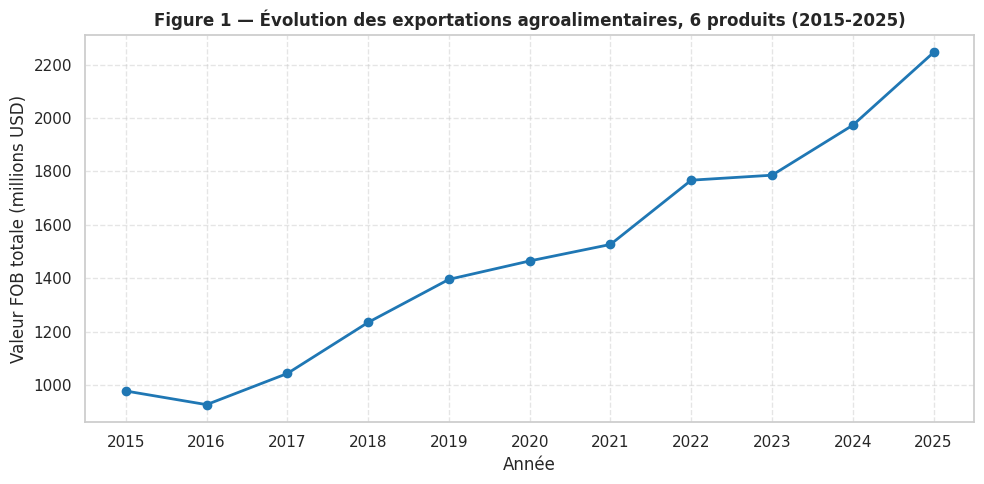

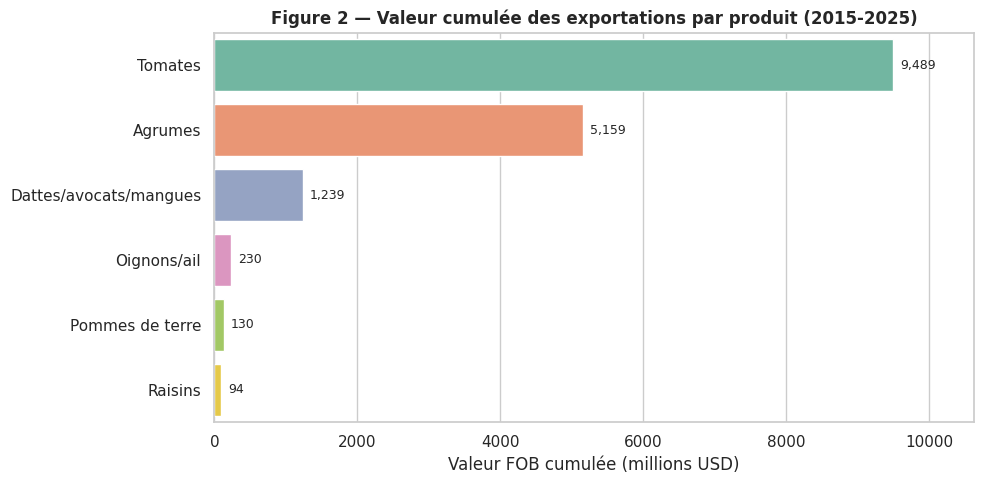

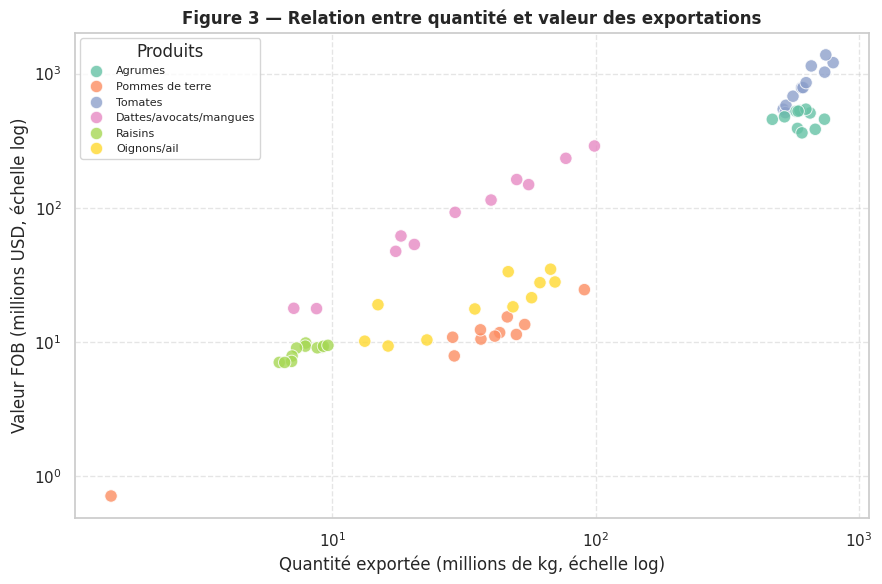

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
Path("figures").mkdir(exist_ok=True)

NOMS = {701: "Pommes de terre", 702: "Tomates", 703: "Oignons/ail",
        804: "Dattes/avocats/mangues", 805: "Agrumes", 806: "Raisins"}

# 1. Valeurs manquantes
print("--- VALEURS MANQUANTES (%), colonnes concernées ---")
manq = df.isna().mean().mul(100).round(1)
print(manq[manq > 0].sort_values(ascending=False))
print("Colonnes constantes :", int((df.nunique() == 1).sum()), "sur", df.shape[1])

# 2. Statistiques descriptives
print("\n--- STATISTIQUES DESCRIPTIVES ---")
display(df[["refYear", "qty", "primaryValue"]].describe().T)

# 3. Doublons (clé pays-partenaire-produit-période)
cles = ["reporterDesc", "partnerDesc", "cmdCode", "period"]
print("\n--- DOUBLONS ---")
print("Doublons sur", cles, ":", df.duplicated(subset=cles).sum())

# 4. Unités, valeurs nulles, flux, partenaires, nomenclature SH
print("\n--- UNITES, NULS, FLUX, NOMENCLATURE ---")
print("Unités de quantité :", df["qtyUnitAbbr"].unique().tolist())
print("Valeurs <= 0 (valeur, quantité) :", int((df["primaryValue"] <= 0).sum()), int((df["qty"] <= 0).sum()))
print("Flux :", df["flowDesc"].unique().tolist(), "| Partenaire :", df["partnerDesc"].unique().tolist())
print("Nomenclature SH par année :", df.groupby("refYear")["classificationCode"].first().to_dict())

# 5. Table de travail pour les figures
df_plot = df.copy()
df_plot["Produit"] = df_plot["cmdCode"].map(NOMS)
df_plot["valeur_unitaire"] = df_plot["primaryValue"] / df_plot["qty"]   # USD/kg

# 6. Valeurs extrêmes
print("\n--- VALEUR UNITAIRE (USD/kg) PAR PRODUIT ---")
display(df_plot.groupby("Produit")["valeur_unitaire"].describe().round(2))
print("\n--- CROISSANCE ANNUELLE (%) PAR PRODUIT ---")
pivot = df_plot.pivot(index="refYear", columns="Produit", values="primaryValue")
display(pivot.pct_change().mul(100).round(0))
print("\n--- POMMES DE TERRE 2022-2024 ---")
display(df_plot[(df_plot["cmdCode"] == 701) & df_plot["refYear"].isin([2022, 2023, 2024])]
        [["refYear", "qty", "primaryValue", "valeur_unitaire"]])

# 7. Corrélation quantité / valeur
print("\n--- CORRELATION QUANTITE / VALEUR ---")
corr_produit = {p: round(g["qty"].corr(g["primaryValue"]), 2) for p, g in df_plot.groupby("Produit")}
print("Par produit :", corr_produit)
print("Global :", round(df_plot["qty"].corr(df_plot["primaryValue"]), 2))

# FIGURE 1 : évolution de la valeur totale
yearly = df_plot.groupby("refYear")["primaryValue"].sum().div(1e6)
plt.figure(figsize=(10, 5))
plt.plot(yearly.index, yearly.values, marker="o", color="#1f77b4", linewidth=2, markersize=6)
plt.title("Figure 1 — Évolution des exportations agroalimentaires, 6 produits (2015-2025)",
          fontsize=12, fontweight="bold")
plt.xlabel("Année")
plt.ylabel("Valeur FOB totale (millions USD)")
plt.xticks(yearly.index.astype(int))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/fig1_evolution_totale.png", dpi=150)
plt.show()

# FIGURE 2 : valeur cumulée par produit
total_produit = (df_plot.groupby("Produit")["primaryValue"].sum()
                 .div(1e6).sort_values(ascending=False).reset_index())
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=total_produit, y="Produit", x="primaryValue",
                 hue="Produit", palette="Set2", legend=False)
for i, v in enumerate(total_produit["primaryValue"]):
    ax.text(v + 100, i, f"{v:,.0f}", va="center", fontsize=9)
ax.set_xlim(0, total_produit["primaryValue"].max() * 1.12)
plt.title("Figure 2 — Valeur cumulée des exportations par produit (2015-2025)",
          fontsize=12, fontweight="bold")
plt.xlabel("Valeur FOB cumulée (millions USD)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("figures/fig2_valeur_par_produit.png", dpi=150)
plt.show()

# FIGURE 3 : quantité contre valeur (échelle log)
df_clean = df_plot.dropna(subset=["qty", "primaryValue", "Produit"])
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_clean, x=df_clean["qty"] / 1e6, y=df_clean["primaryValue"] / 1e6,
                hue="Produit", s=80, alpha=0.8, palette="Set2")
plt.xscale("log")
plt.yscale("log")
plt.title("Figure 3 — Relation entre quantité et valeur des exportations",
          fontsize=12, fontweight="bold")
plt.xlabel("Quantité exportée (millions de kg, échelle log)")
plt.ylabel("Valeur FOB (millions USD, échelle log)")
plt.legend(title="Produits", fontsize=8, loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/fig3_quantite_valeur.png", dpi=150)
plt.show()


## 4. Préparation et découpage sans fuite

- **Traitements réalisés :** Vérification des doublons sur la clé pays–partenaire–produit–période : aucun (0 doublon). Conversion des quantités de kilogrammes en tonnes, puis passage de la valeur FOB (USD) et de la quantité (t) en logarithme, en raison des écarts d'échelle entre produits (de 0,7 M à 1 378 M USD). Tri chronologique par pays déclarant, partenaire, produit et année. Création de variables retardées (*lag 1*) : le logarithme de la valeur (`lag1_log_value`) et de la quantité (`lag1_log_qty`) de l'année précédente, calculés par produit avec le passé uniquement. Les six observations de 2015 sont écartées faute d'année précédente ; il reste 60 lignes (2016–2025). Le pipeline inclut une imputation (médiane pour le numérique, valeur la plus fréquente pour le catégoriel) par précaution, car aucune valeur manquante n'existe dans les colonnes retenues, ainsi que la standardisation des variables numériques et l'encodage One-Hot du code produit. Les colonnes constantes ou très incomplètes (`cifvalue`, `grossWgt`, `altQty`) ne sont pas utilisées.

- **Valeurs extrêmes :** les pommes de terre en 2023 (0,7 M USD) et les oignons/ail en 2023 (valeur unitaire de 1,27 USD/kg) sont conservés : aucune erreur d'unité n'a été détectée et ce sont des observations réelles de UN Comtrade. Le logarithme réduit leur influence. Leur effet sur les erreurs de prévision sera discuté dans l'analyse des erreurs.

- **Stratégie de découpage :** découpage strictement chronologique, sans mélange aléatoire :
  - **Entraînement :** 2016–2021 (36 lignes)
  - **Validation :** 2022–2023 (12 lignes), pour le réglage de `alpha` et `max_depth`
  - **Test :** 2024–2025 (12 lignes), utilisé une seule fois à la fin

- **Contrôle de fuite :** les variables retardées sont calculées séparément pour chaque produit, avec les seules années précédentes. L'imputation, la standardisation et l'encodage sont ajustés (`fit`) sur le jeu d'entraînement uniquement, puis appliqués (`transform`) à la validation et au test. La quantité et la valeur de l'année en cours ne servent pas de variables explicatives. Une vérification (`assert`) confirme que train < validation < test dans le temps. Graine aléatoire : 42.

- **Limite :** avec 36 lignes d'entraînement et 12 de test, les résultats seront sensibles au découpage.

In [6]:

# ==============================================================================
# SECTION 4 : Préparation et découpage sans fuite
# Projet CI12 : Exportations agroalimentaires
# ==============================================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

SEED = 42
np.random.seed(SEED)

# 1. Copie et préparation initiale
df_prep = df.copy()
df_prep["refYear"] = pd.to_numeric(df_prep["refYear"], errors="coerce")
df_prep["primaryValue"] = pd.to_numeric(df_prep["primaryValue"], errors="coerce")
df_prep["qty"] = pd.to_numeric(df_prep["qty"], errors="coerce")
df_prep["cmdCode"] = df_prep["cmdCode"].astype(str)

# 2. Suppression des doublons
cles = ["reporterDesc", "partnerDesc", "cmdCode", "period"]
nb_avant = len(df_prep)
df_prep = df_prep.drop_duplicates(subset=cles, keep="first").copy()
print("--- SUPPRESSION DES DOUBLONS ---")
print("Nombre de doublons supprimés :", nb_avant - len(df_prep))

# 3. Conversion des unités : kg en tonnes, valeur et quantité en logarithme
df_prep["qty_tonnes"] = df_prep["qty"] / 1000
df_prep["log_value"] = np.log(df_prep["primaryValue"])
df_prep["log_qty_tonnes"] = np.log(df_prep["qty_tonnes"])
print("\n--- CONVERSION DES UNITÉS ---")
print("Quantité : kg -> tonnes ; valeur (USD) et quantité (t) passées en logarithme")

# 4. Variables retardées (lag 1), calculées par produit avec le passé uniquement
group_cols = ["reporterDesc", "partnerDesc", "cmdCode"]
df_prep = df_prep.sort_values(group_cols + ["refYear"]).copy()
df_prep["lag1_log_value"] = df_prep.groupby(group_cols)["log_value"].shift(1)
df_prep["lag1_log_qty"] = df_prep.groupby(group_cols)["log_qty_tonnes"].shift(1)

df_model = df_prep.dropna(
    subset=["refYear", "cmdCode", "log_value", "lag1_log_value", "lag1_log_qty"]
).copy()

print("\n--- DONNÉES APRÈS PRÉPARATION ---")
print("Nombre de lignes initial :", len(df))
print("Nombre de lignes préparées :", len(df_model))

# 5. Variables X et cible y (log de la valeur FOB)
features_numeriques = ["refYear", "lag1_log_value", "lag1_log_qty"]
features_categorielles = ["cmdCode"]
cible = "log_value"
print("\nVariables explicatives :", features_numeriques + features_categorielles)
print("Variable cible : log(primaryValue)")

# 6. Découpage chronologique : Train / Validation / Test
train_df = df_model[df_model["refYear"] <= 2021].copy()
val_df = df_model[df_model["refYear"].between(2022, 2023)].copy()
test_df = df_model[df_model["refYear"] >= 2024].copy()

cols = features_numeriques + features_categorielles
X_train, y_train = train_df[cols], train_df[cible]
X_val, y_val = val_df[cols], val_df[cible]
X_test, y_test = test_df[cols], test_df[cible]

assert train_df["refYear"].max() < val_df["refYear"].min() < test_df["refYear"].min()

print("\n--- DÉCOUPAGE CHRONOLOGIQUE ---")
print("Train      :", int(train_df["refYear"].min()), "-", int(train_df["refYear"].max()), "|", len(X_train), "lignes")
print("Validation :", int(val_df["refYear"].min()), "-", int(val_df["refYear"].max()), "|", len(X_val), "lignes")
print("Test       :", int(test_df["refYear"].min()), "-", int(test_df["refYear"].max()), "|", len(X_test), "lignes")

# 7. Pipeline de préparation
pipeline_numerique = Pipeline(steps=[
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])
pipeline_categoriel = Pipeline(steps=[
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numerique", pipeline_numerique, features_numeriques),
    ("categoriel", pipeline_categoriel, features_categorielles)
])

# 8. Contrôle de fuite : fit sur Train uniquement
X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)

print("\n--- CONTRÔLE DE FUITE DE DONNÉES ---")
print("Préparation ajustée uniquement sur Train ; Validation et Test transformés sans réajustement.")
print("X_train :", X_train_prepared.shape, "| X_val :", X_val_prepared.shape, "| X_test :", X_test_prepared.shape)
print("\n--- SECTION 4 TERMINÉE ---")


--- SUPPRESSION DES DOUBLONS ---
Nombre de doublons supprimés : 0

--- CONVERSION DES UNITÉS ---
Quantité : kg -> tonnes ; valeur (USD) et quantité (t) passées en logarithme

--- DONNÉES APRÈS PRÉPARATION ---
Nombre de lignes initial : 66
Nombre de lignes préparées : 60

Variables explicatives : ['refYear', 'lag1_log_value', 'lag1_log_qty', 'cmdCode']
Variable cible : log(primaryValue)

--- DÉCOUPAGE CHRONOLOGIQUE ---
Train      : 2016 - 2021 | 36 lignes
Validation : 2022 - 2023 | 12 lignes
Test       : 2024 - 2025 | 12 lignes

--- CONTRÔLE DE FUITE DE DONNÉES ---
Préparation ajustée uniquement sur Train ; Validation et Test transformés sans réajustement.
X_train : (36, 9) | X_val : (12, 9) | X_test : (12, 9)

--- SECTION 4 TERMINÉE ---



## 5. Algorithme principal (un des 29 du cours)

**Algorithme / numéro :** Régression Ridge (régression linéaire régularisée L2), algorithme n° [numéro dans la liste du cours].

**Pourquoi lui ? Alternative plausible écartée :**
Le jeu d'entraînement est petit (36 lignes) et les deux variables retardées, valeur et quantité de l'année précédente, sont fortement corrélées entre elles. Une régression linéaire ordinaire donnerait alors des coefficients instables. Ridge pénalise la taille des coefficients et stabilise l'estimation, ce qui limite le surapprentissage. Le lien entre la valeur d'une année et celle de l'année précédente est quasi linéaire en logarithme (corrélation d'environ 0,95), ce qui convient à un modèle linéaire. Enfin, les coefficients sont lisibles, ce qui permet d'expliquer l'effet de chaque produit et de la tendance. L'alternative comparée est la forêt aléatoire (Random Forest), qui capte des relations non linéaires et des interactions entre produits. Elle est écartée comme modèle principal pour deux raisons : un arbre ne prédit jamais au-delà des valeurs vues à l'entraînement, alors que les exportations de tomates continuent de croître et dépassent leurs niveaux d'entraînement en 2024-2025 ; et elle demande plus de données pour être fiable. Elle reste utile pour vérifier si la non-linéarité améliore la prévision. La référence naïve (persistance : valeur de l'année précédente) sert de point de comparaison dans tous les cas.

**Équation et définition de tous les symboles :**

$$\hat{\beta} = \arg\min_{\beta_0,\beta}\; \sum_{i=1}^{n}\Big(y_i - \beta_0 - \sum_{j=1}^{p}\beta_j x_{ij}\Big)^2 \;+\; \alpha \sum_{j=1}^{p}\beta_j^2$$

Prévision : $\hat{y}_i = \beta_0 + \sum_{j=1}^{p}\beta_j x_{ij}$, puis valeur en USD : $\exp(\hat{y}_i)$.

- $n$ : nombre d'observations d'entraînement (36 lignes : produit × année).
- $p$ : nombre de variables explicatives après prétraitement (9 : trois numériques et six produits encodés).
- $y_i$ : logarithme de la valeur FOB exportée (cible) de l'observation $i$.
- $x_{ij}$ : valeur de la variable $j$ pour l'observation $i$ (`lag1_log_value`, `lag1_log_qty`, `refYear` standardisées, et indicatrices de produit).
- $\beta_0$ : constante (ordonnée à l'origine), non pénalisée.
- $\beta_j$ : coefficient de la variable $j$.
- $\hat{y}_i$ : prévision du logarithme de la valeur.
- $\alpha \ge 0$ : force de la pénalisation (hyperparamètre).

**Paramètres appris :** la constante $\beta_0$ et les coefficients $\beta_1,\dots,\beta_p$, estimés sur le jeu d'entraînement (solution explicite $\hat{\beta} = (X^\top X + \alpha I)^{-1}X^\top y$ sur variables centrées). Le prétraitement (moyennes et écarts-types de la standardisation, modalités de l'encodage) est appris sur le train uniquement.

**Deux hyperparamètres et valeurs envisagées :**
- **`alpha` (Ridge) : {0,01 ; 0,1 ; 1 ; 10 ; 100}.** Un petit `alpha` rapproche le modèle des moindres carrés (risque de surapprentissage), un grand `alpha` écrase les coefficients vers 0 (risque de sous-apprentissage). Choisi sur la validation 2022-2023.
- **`max_depth` (Random Forest, alternative) : {2 ; 3 ; 5 ; None}.** Une faible profondeur donne des arbres simples et stables, une grande profondeur permet d'ajuster le bruit. Choisi sur la validation 2022-2023 ; le nombre d'arbres est fixé (`n_estimators` = 300, graine 42).

**Schéma explicatif personnel :** voir la figure ci-dessous (cellule suivante). Elle résume la chaîne : variables retardées, prétraitement ajusté sur le train, ajustement de Ridge, choix de `alpha` sur la validation, puis test final unique en 2024-2025 avec retour en USD par `exp`.



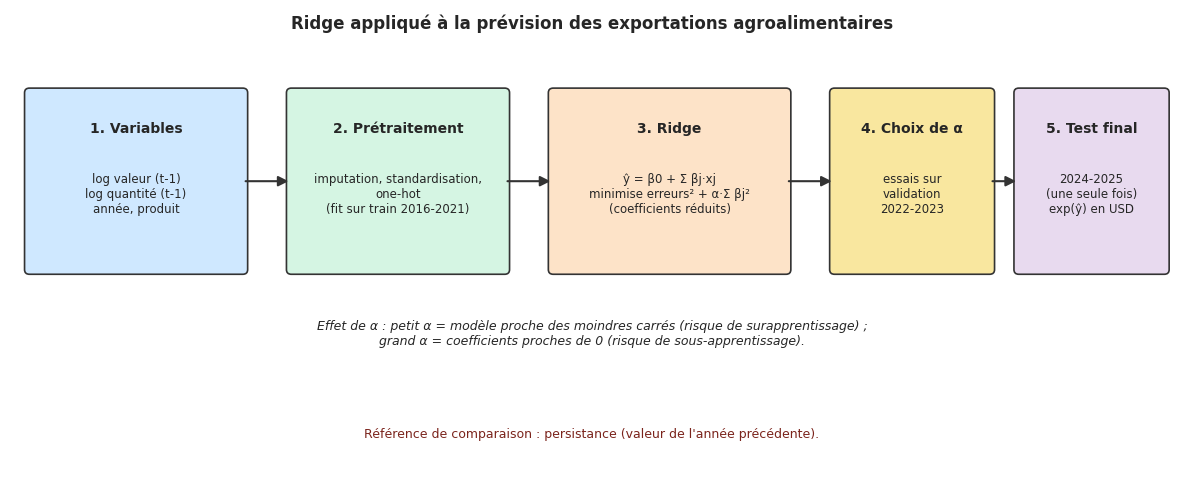

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

Path("figures").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 5.2); ax.axis("off")

def boite(x, y, w, h, titre, contenu, couleur):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05",
                                fc=couleur, ec="#333333", lw=1.2))
    ax.text(x + w/2, y + h - 0.3, titre, ha="center", va="top", fontsize=10, fontweight="bold")
    ax.text(x + w/2, y + h - 0.85, contenu, ha="center", va="top", fontsize=8.5)

def fleche(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=15, lw=1.5, color="#333333"))

ax.text(6, 5.0, "Ridge appliqué à la prévision des exportations agroalimentaires",
        ha="center", fontsize=12, fontweight="bold")
boite(0.2, 2.4, 2.2, 1.9, "1. Variables", "log valeur (t-1)\nlog quantité (t-1)\nannée, produit", "#cfe8ff")
boite(2.9, 2.4, 2.2, 1.9, "2. Prétraitement", "imputation, standardisation,\none-hot\n(fit sur train 2016-2021)", "#d5f5e3")
boite(5.6, 2.4, 2.4, 1.9, "3. Ridge", "ŷ = β0 + Σ βj·xj\nminimise erreurs² + α·Σ βj²\n(coefficients réduits)", "#fde3c8")
boite(8.5, 2.4, 1.6, 1.9, "4. Choix de α", "essais sur\nvalidation\n2022-2023", "#f9e79f")
boite(10.4, 2.4, 1.5, 1.9, "5. Test final", "2024-2025\n(une seule fois)\nexp(ŷ) en USD", "#e8daef")
for x1, x2 in [(2.4, 2.9), (5.1, 5.6), (8.0, 8.5), (10.1, 10.4)]:
    fleche(x1, 3.35, x2, 3.35)
ax.text(6, 1.6, "Effet de α : petit α = modèle proche des moindres carrés (risque de surapprentissage) ;\n"
                "grand α = coefficients proches de 0 (risque de sous-apprentissage).",
        ha="center", fontsize=9, style="italic")
ax.text(6, 0.6, "Référence de comparaison : persistance (valeur de l'année précédente).",
        ha="center", fontsize=9, color="#7b241c")
plt.tight_layout()
plt.savefig("figures/fig_schema_ridge.png", dpi=150)
plt.show()

## 6. Protocole expérimental

**Référence naïve ou méthode de référence :** persistance. La valeur prévue pour une année est la valeur de l'année précédente du même produit (en logarithme : `lag1_log_value`). Elle ne contient aucun paramètre à apprendre. Les modèles comparés sont Ridge (algorithme principal) et Random Forest (alternative).

**Protocole de validation :**
- Découpage chronologique, sans mélange : entraînement 2016–2021 (36 lignes), validation 2022–2023 (12 lignes), test 2024–2025 (12 lignes).
- Réglage de `alpha` (Ridge : 0,01 ; 0,1 ; 1 ; 10 ; 100) et de `max_depth` (Random Forest : 2 ; 3 ; 5 ; None) : chaque modèle est ajusté sur l'entraînement et évalué sur la validation. La valeur qui minimise le RMSE de validation est retenue. Le test n'intervient à aucun moment dans ce choix.
- Une fois les réglages figés, les deux modèles sont ré-ajustés sur 2016–2023 (entraînement + validation), avec un prétraitement ré-ajusté sur ces seules années. Ils sont évalués une seule fois sur le test 2024–2025 (section 7).
- Surapprentissage : l'écart entre le RMSE d'entraînement et celui de validation est examiné pour chaque réglage.
- Graine aléatoire : 42 (`n_estimators` = 300 pour la forêt).

**Métrique principale :** RMSE sur le logarithme de la valeur FOB, calculé sur le test 2024–2025. Un RMSE de 0,1 correspond à une erreur relative d'environ 10 %. Seuil de réussite annoncé à l'avance : RMSE du modèle ≤ 0,80 × RMSE de la persistance.

**Métriques secondaires :**
- MAE sur le logarithme de la valeur : moins sensible aux valeurs extrêmes que le RMSE.
- R² : à interpréter avec prudence, car il est élevé dès que le modèle distingue les produits entre eux (la valeur des tomates est sans rapport avec celle des pommes de terre). La comparaison avec la persistance reste le critère décisif.

**Pour CI31–CI40 :** non applicable (CI12 est un projet de régression/prévision).

In [8]:

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

def scores(y, p):
    return {"RMSE": rmse(y, p), "MAE": float(mean_absolute_error(y, p)), "R2": float(r2_score(y, p))}

# 1. Référence naïve : persistance (valeur prévue = valeur de l'année précédente, en log)
ref_train = X_train["lag1_log_value"]
ref_val = X_val["lag1_log_value"]

# 2. Réglage de alpha (Ridge) : entraînement sur Train, choix sur Validation
grille_alpha = [0.01, 0.1, 1, 10, 100]
res_ridge = []
for a in grille_alpha:
    m = Pipeline([("prep", clone(preprocessor)), ("model", Ridge(alpha=a))])
    m.fit(X_train, y_train)
    res_ridge.append({"alpha": a,
                      "RMSE_train": rmse(y_train, m.predict(X_train)),
                      "RMSE_val": rmse(y_val, m.predict(X_val))})
res_ridge = pd.DataFrame(res_ridge)
best_alpha = grille_alpha[int(np.argmin(res_ridge["RMSE_val"]))]

# 3. Réglage de max_depth (Random Forest) : mêmes règles
grille_depth = [2, 3, 5, None]
res_rf = []
for d in grille_depth:
    m = Pipeline([("prep", clone(preprocessor)),
                  ("model", RandomForestRegressor(n_estimators=300, max_depth=d, random_state=SEED))])
    m.fit(X_train, y_train)
    res_rf.append({"max_depth": str(d),
                   "RMSE_train": rmse(y_train, m.predict(X_train)),
                   "RMSE_val": rmse(y_val, m.predict(X_val))})
res_rf = pd.DataFrame(res_rf)
best_depth = grille_depth[int(np.argmin(res_rf["RMSE_val"]))]

print("--- REGLAGE DE alpha (Ridge) ---")
display(res_ridge.round(4))
print("alpha retenu :", best_alpha)
print("\n--- REGLAGE DE max_depth (Random Forest) ---")
display(res_rf.round(4))
print("max_depth retenu :", best_depth)

# 4. Comparaison sur la validation (aucun usage du test)
m_ridge_val = Pipeline([("prep", clone(preprocessor)), ("model", Ridge(alpha=best_alpha))]).fit(X_train, y_train)
m_rf_val = Pipeline([("prep", clone(preprocessor)),
                     ("model", RandomForestRegressor(n_estimators=300, max_depth=best_depth, random_state=SEED))]).fit(X_train, y_train)

tab_val = pd.DataFrame({
    "Persistance (référence)": scores(y_val, ref_val),
    "Ridge": scores(y_val, m_ridge_val.predict(X_val)),
    "Random Forest": scores(y_val, m_rf_val.predict(X_val)),
}).T
print("\n--- COMPARAISON SUR LA VALIDATION (2022-2023) ---")
display(tab_val.round(4))

# 5. Modèles finaux : réglages figés, ré-ajustement sur Train + Validation (le test n'est pas utilisé)
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])
modele_ridge = Pipeline([("prep", clone(preprocessor)), ("model", Ridge(alpha=best_alpha))]).fit(X_trval, y_trval)
modele_rf = Pipeline([("prep", clone(preprocessor)),
                      ("model", RandomForestRegressor(n_estimators=300, max_depth=best_depth, random_state=SEED))]).fit(X_trval, y_trval)

print("\nModèles finaux ajustés sur 2016-2023. Le test (2024-2025) reste intact pour la section 7.")

--- REGLAGE DE alpha (Ridge) ---


,alpha,RMSE_train,RMSE_val
0,0.01,0.2508,0.9681
1,0.10,0.2579,0.9424
2,1.00,0.2878,0.9376
3,10.00,0.4164,1.1028
4,100.00,1.0756,1.6476


alpha retenu : 1

--- REGLAGE DE max_depth (Random Forest) ---


,max_depth,RMSE_train,RMSE_val
0,2,0.3002,0.9360
1,3,0.2177,0.9277
2,5,0.1604,0.9428
3,None,0.1490,0.9454


max_depth retenu : 3

--- COMPARAISON SUR LA VALIDATION (2022-2023) ---


,RMSE,MAE,R2
Persistance (référence),0.8763,0.4045,0.8449
Ridge,0.9376,0.4487,0.8225
Random Forest,0.9277,0.4774,0.8262



Modèles finaux ajustés sur 2016-2023. Le test (2024-2025) reste intact pour la section 7.


## 7. Résultats et interprétation

Métrique principale : RMSE sur le logarithme de la valeur FOB (sans unité ; 0,1 correspond à environ 10 % d'erreur relative). Validation : modèles ajustés sur 2016-2021, évalués sur 2022-2023. Test final : modèles ajustés sur 2016-2023, évalués une seule fois sur 2024-2025.

| Méthode | RMSE validation | RMSE test final | MAE test | R² test | Interprétation |
|---|---:|---:|---:|---:|---|
| Référence naïve (persistance) | 0,876 | 0,856 | 0,402 | 0,795 | Très précise sur les produits stables (erreur de 0,07 pour les agrumes et 0,10 pour les tomates), mais très mauvaise pour les pommes de terre (1,49) |
| Modèle principal (Ridge, alpha = 1) | 0,938 | 0,982 | 0,643 | 0,730 | Moins bon que la persistance sur toutes les métriques ; rapport 0,982 / 0,856 = 1,15, donc le seuil de réussite (≤ 0,80) n'est pas atteint |
| Alternative (Random Forest, profondeur 3) | 0,928 | 0,653 | 0,555 | 0,880 | RMSE inférieur de 24 % à la persistance, mais MAE plus élevée ; l'avantage vient d'un seul produit (voir ci-dessous) |

**Figure des résultats :** voir la Figure 4 (cellule précédente) : (a) RMSE et MAE de chaque méthode sur le test ; (b) erreur absolue moyenne par produit.

**Analyse des erreurs, du surapprentissage ou de la robustesse :**
- **Les pommes de terre dominent le RMSE.** Leur valeur s'effondre en 2023 (0,7 M USD, contre 13,5 M USD en 2022) puis remonte en 2024 (12,3 M USD). La persistance, qui reprend la valeur de l'année précédente, se trompe donc beaucoup en 2024 (erreur absolue moyenne de 1,49 sur ce produit). Le Random Forest, qui ne copie pas le retard, fait mieux sur ce seul produit (0,90) : c'est ce qui lui donne le meilleur RMSE.
- **Sans les pommes de terre, la persistance gagne nettement** : RMSE de test de 0,257 contre 0,464 (Ridge) et 0,590 (Random Forest). Le Random Forest ne bat donc pas la référence de manière générale : il la bat à cause d'un seul produit atypique. Sa MAE (0,555) reste d'ailleurs plus élevée que celle de la persistance (0,402).
- **Ridge sous-estime les produits en croissance.** Pour les tomates, il prévoit 860 M USD en 2024 et 882 M USD en 2025 pour des valeurs réelles de 1 206 et 1 378 M USD ; pour les agrumes, 351 M USD contre 477 et 525. Un modèle linéaire régularisé, qui ramène les coefficients vers zéro, suit mal une série qui sort de sa plage d'entraînement.
- **Random Forest ne suit pas la croissance non plus** : ses prévisions pour les tomates restent proches de 890 M USD en 2024 comme en 2025 (891 et 893), car un arbre ne prédit jamais au-delà des valeurs vues à l'entraînement. Il est en revanche très bon pour les agrumes (erreur de 0,048), dont la valeur est stable.
- **Surapprentissage :** pour les réglages retenus, le RMSE passe de 0,288 (entraînement) à 0,938 (validation) pour Ridge, et de 0,218 à 0,928 pour le Random Forest. L'écart est grand, mais il est en grande partie dû à l'observation « pommes de terre 2023 », très éloignée de la valeur de l'année précédente. Avec 36 lignes d'entraînement et 12 de validation, ces chiffres restent peu stables.
- **Robustesse :** le classement des méthodes change selon la métrique (RMSE : Random Forest d'abord ; MAE et RMSE sans pommes de terre : persistance d'abord). Les conclusions ne sont donc pas robustes à un seul indicateur.

**Illustration sur des observations non vues (tomates et agrumes, 2024-2025, en millions USD) :**
- Tomates 2025 : valeur réelle 1 378, persistance 1 206, Ridge 882, Random Forest 893.
- Agrumes 2025 : valeur réelle 525, persistance 477, Ridge 351, Random Forest 488.

Pour ces deux produits, qui représentent environ 90 % de la valeur cumulée exportée, la persistance est la plus proche de la réalité pour les tomates ; pour les agrumes, la persistance (477) et le Random Forest (488) sont proches, mais le Random Forest sous-estime légèrement et ne suit pas la hausse.

--- TABLEAU COMPARATIF (métrique principale : RMSE sur log de la valeur) ---


,Méthode,RMSE validation,RMSE test,MAE test,R² test
0,Persistance (référence),0.8763,0.8563,0.4022,0.7946
1,Ridge,0.9376,0.9823,0.6431,0.7297
2,Random Forest,0.9277,0.6534,0.5552,0.8804



RMSE Ridge / RMSE persistance (test) = 1.147  (seuil de réussite annoncé : <= 0.80)
Seuil atteint : False

--- ERREUR ABSOLUE MOYENNE (log) PAR PRODUIT, TEST 2024-2025 ---


,err_abs Persistance (référence),err_abs Ridge,err_abs Random Forest
Produit,,,
Agrumes,0.070,0.354,0.048
Dattes/avocats/mangues,0.288,0.467,0.519
Oignons/ail,0.326,0.550,1.065
Pommes de terre,1.489,1.717,0.903
Raisins,0.147,0.378,0.428
Tomates,0.095,0.392,0.368



--- RMSE TEST SANS POMMES DE TERRE (analyse de sensibilité) ---
{'Persistance (référence)': 0.2567, 'Ridge': 0.4636, 'Random Forest': 0.59}

--- SURAPPRENTISSAGE (réglages retenus) ---
Ridge         : {'RMSE_train': 0.2878, 'RMSE_val': 0.9376}
Random Forest : {'RMSE_train': 0.2177, 'RMSE_val': 0.9277}


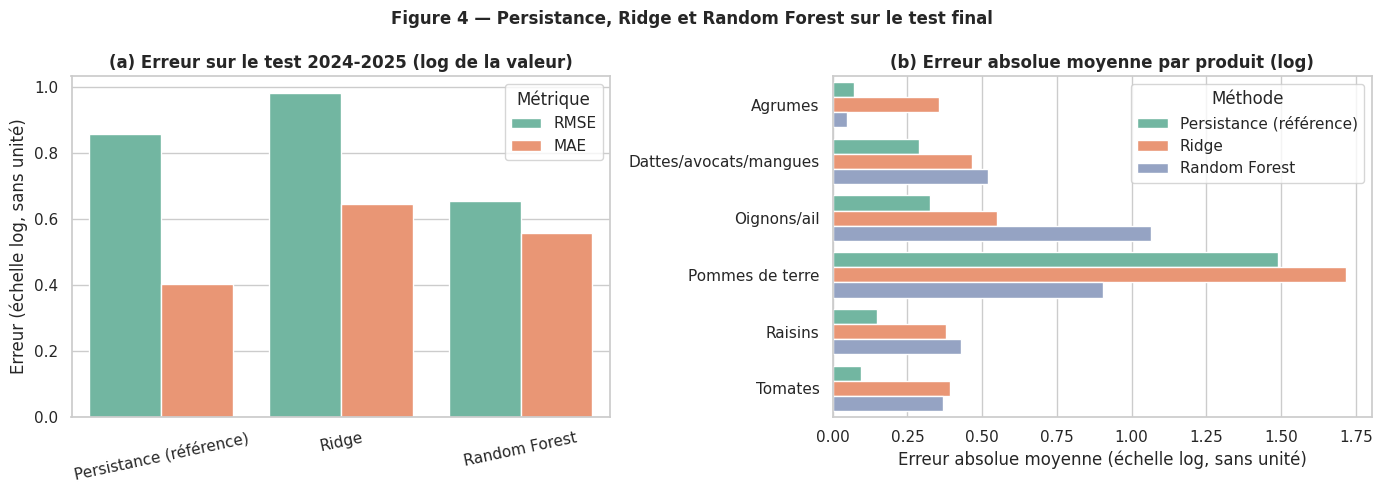


--- ILLUSTRATION : TOMATES ET AGRUMES (observations non vues) ---


,Année,Produit,Valeur réelle (M USD),Persistance (M USD),Ridge (M USD),Random Forest (M USD)
2,2024,Agrumes,477.0,456.0,351.0,488.0
3,2025,Agrumes,525.0,477.0,351.0,488.0
0,2024,Tomates,1206.0,1140.0,860.0,891.0
1,2025,Tomates,1378.0,1206.0,882.0,893.0


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

Path("figures").mkdir(exist_ok=True)
NOMS = {701: "Pommes de terre", 702: "Tomates", 703: "Oignons/ail",
        804: "Dattes/avocats/mangues", 805: "Agrumes", 806: "Raisins"}

# 1. Prévisions sur le test final (2024-2025), évaluées une seule fois
ref_test = X_test["lag1_log_value"]
pred_test = {
    "Persistance (référence)": ref_test,
    "Ridge": modele_ridge.predict(X_test),
    "Random Forest": modele_rf.predict(X_test),
}
tab_test = pd.DataFrame({k: scores(y_test, v) for k, v in pred_test.items()}).T

# 2. Tableau comparatif réel : validation (modèles ajustés sur Train) et test (ajustés sur Train+Validation)
resultats = pd.DataFrame({
    "Méthode": tab_test.index,
    "RMSE validation": tab_val["RMSE"].values,
    "RMSE test": tab_test["RMSE"].values,
    "MAE test": tab_test["MAE"].values,
    "R² test": tab_test["R2"].values,
}).round(4)
print("--- TABLEAU COMPARATIF (métrique principale : RMSE sur log de la valeur) ---")
display(resultats)

ratio = tab_test.loc["Ridge", "RMSE"] / tab_test.loc["Persistance (référence)", "RMSE"]
print(f"\nRMSE Ridge / RMSE persistance (test) = {ratio:.3f}  (seuil de réussite annoncé : <= 0.80)")
print("Seuil atteint :", bool(ratio <= 0.80))

# 3. Erreurs détaillées par observation
err = test_df[["refYear", "cmdCode"]].copy()
err["Produit"] = err["cmdCode"].astype(int).map(NOMS)
err["y_reel_log"] = y_test.values
for k, v in pred_test.items():
    err[k] = np.asarray(v)
    err["err_abs " + k] = (err[k] - err["y_reel_log"]).abs()

erreurs_produit = (err.groupby("Produit")[[c for c in err.columns if c.startswith("err_abs")]]
                   .mean().round(3))
print("\n--- ERREUR ABSOLUE MOYENNE (log) PAR PRODUIT, TEST 2024-2025 ---")
display(erreurs_produit)

# 4. Sensibilité : sans les pommes de terre (analyse complémentaire, la métrique principale reste inchangée)
sans_pdt = err["cmdCode"].astype(int) != 701
sens = {k: rmse(err.loc[sans_pdt, "y_reel_log"], err.loc[sans_pdt, k]) for k in pred_test}
print("\n--- RMSE TEST SANS POMMES DE TERRE (analyse de sensibilité) ---")
print({k: round(v, 4) for k, v in sens.items()})

# 5. Surapprentissage : RMSE entraînement contre validation pour les réglages retenus
print("\n--- SURAPPRENTISSAGE (réglages retenus) ---")
print("Ridge         :", res_ridge[res_ridge["alpha"] == best_alpha][["RMSE_train", "RMSE_val"]].round(4).to_dict("records")[0])
print("Random Forest :", res_rf[res_rf["max_depth"] == str(best_depth)][["RMSE_train", "RMSE_val"]].round(4).to_dict("records")[0])

# 6. Figure des résultats
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metr = tab_test[["RMSE", "MAE"]].reset_index().melt(id_vars="index", var_name="Métrique", value_name="Valeur")
sns.barplot(data=metr, x="index", y="Valeur", hue="Métrique", palette="Set2", ax=axes[0])
axes[0].set_title("(a) Erreur sur le test 2024-2025 (log de la valeur)", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Erreur (échelle log, sans unité)")
axes[0].tick_params(axis="x", rotation=12)

ep = erreurs_produit.reset_index().melt(id_vars="Produit", var_name="Méthode", value_name="Erreur absolue")
ep["Méthode"] = ep["Méthode"].str.replace("err_abs ", "", regex=False)
sns.barplot(data=ep, y="Produit", x="Erreur absolue", hue="Méthode", palette="Set2", ax=axes[1])
axes[1].set_title("(b) Erreur absolue moyenne par produit (log)", fontweight="bold")
axes[1].set_xlabel("Erreur absolue moyenne (échelle log, sans unité)")
axes[1].set_ylabel("")

plt.suptitle("Figure 4 — Persistance, Ridge et Random Forest sur le test final", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/fig4_resultats_test.png", dpi=150)
plt.show()

# 7. Illustration sur observations non vues : tomates et agrumes, 2024-2025 (millions USD)
illus = err[err["cmdCode"].astype(int).isin([702, 805])].copy()
tab_illus = pd.DataFrame({
    "Année": illus["refYear"].astype(int).values,
    "Produit": illus["Produit"].values,
    "Valeur réelle (M USD)": np.exp(illus["y_reel_log"]).values / 1e6,
    "Persistance (M USD)": np.exp(illus["Persistance (référence)"]).values / 1e6,
    "Ridge (M USD)": np.exp(illus["Ridge"]).values / 1e6,
    "Random Forest (M USD)": np.exp(illus["Random Forest"]).values / 1e6,
}).sort_values(["Produit", "Année"]).round(0)
print("\n--- ILLUSTRATION : TOMATES ET AGRUMES (observations non vues) ---")
display(tab_illus)

## 8. Analyse critique

**Limites des données et de leur représentativité :**
- **Très peu d'observations.** Le jeu de données contient 66 lignes (6 produits × 11 années), soit 60 utilisables après la création du retard : 36 pour l'entraînement, 12 pour la validation et 12 pour le test. Les scores calculés sur 12 points sont instables : une seule observation peut changer le classement des méthodes, comme on le voit avec les pommes de terre.
- **Périmètre limité.** Seuls six produits (HS 0701, 0702, 0703, 0804, 0805, 0806) sont étudiés, et uniquement les exportations du Maroc vers le monde. Ils ne représentent pas l'ensemble des exportations agroalimentaires marocaines, et le partenaire unique « Monde » masque les différences entre marchés (Union européenne, Afrique, etc.). Il n'y a pas non plus de flux miroir pour vérifier les valeurs déclarées.
- **Données agrégées et en dollars courants.** La fréquence annuelle cache les effets de saison (campagnes de tomates et d'agrumes). La valeur en USD courants mélange l'effet des volumes, des prix et du taux de change : la hausse des tomates vient en partie de la valeur unitaire (de 1,05 à 1,84 USD/kg).
- **Valeurs atypiques non expliquées.** La chute des pommes de terre en 2023 (0,7 M USD) et la valeur unitaire élevée des oignons/ail la même année sont conservées, car aucune erreur de saisie n'a été détectée. Leur cause n'a pas été vérifiée avec une source indépendante (Office des Changes, presse économique). Les statistiques de commerce peuvent aussi être révisées après publication.
- **Changements de nomenclature.** Les codes à 4 chiffres existent dans les versions H4, H5 et H6 du SH, mais leur contenu précis peut avoir changé légèrement entre versions ; ce point n'a pas été testé au niveau des sous-positions.

**Limites méthodologiques / risques d'erreurs :**
- **Réglage influencé par une seule observation.** La validation (2022-2023) contient la chute des pommes de terre de 2023, dont l'erreur est très supérieure à toutes les autres. Le choix de `alpha` et de `max_depth` repose donc en grande partie sur ce point, et la différence entre les valeurs essayées est faible.
- **Écart important entre entraînement et validation.** Le RMSE passe de 0,288 à 0,938 pour Ridge et de 0,218 à 0,928 pour le Random Forest, ce qui signale du surapprentissage ou un changement de régime entre les périodes.
- **Un seul découpage.** Le protocole utilise un seul découpage chronologique, sans validation à origine glissante, et aucun intervalle d'incertitude n'est calculé. Les écarts entre méthodes ne sont pas testés statistiquement.
- **Une seule variable retardée.** Le modèle ne reçoit que le retard d'un an (valeur et quantité). Il ne dispose d'aucune information sur les prix, la production, la demande des pays importateurs ou le taux de change.
- **Modèles peu adaptés à la tendance.** Ridge sous-estime les tomates et les agrumes (882 M USD prévus pour 1 378 M USD réels en 2025 pour les tomates) et le Random Forest ne dépasse pas les valeurs vues à l'entraînement (environ 890 M USD). Les deux modèles apprennent un niveau moyen par produit au lieu de corriger la valeur de l'année précédente.
- **Indicateurs pouvant tromper.** Le R² est élevé (0,73 à 0,88) pour toutes les méthodes, car il mesure surtout la différence d'échelle entre produits. Le RMSE du Random Forest est meilleur que celui de la persistance, mais sa MAE est moins bonne et, sans les pommes de terre, son RMSE est plus de deux fois plus élevé (0,590 contre 0,257). Le choix de l'indicateur change donc la conclusion.
- **Choix du modèle principal.** Ridge avait été désigné modèle principal avant l'évaluation, et il est conservé comme tel même si le Random Forest obtient un meilleur RMSE, afin de ne pas choisir le modèle d'après le test.

**Deux améliorations concrètes :**
1. **Prévoir la variation plutôt que le niveau.** Prendre comme cible la différence de logarithmes entre l'année t et l'année t-1 (taux de croissance), puis ajouter cette prévision à la valeur de l'année précédente. Le modèle corrigerait ainsi la persistance au lieu de la remplacer, ce qui traiterait directement la sous-estimation des tomates et des agrumes. Utiliser en parallèle une validation à origine glissante (plusieurs années de test successives) et une perte robuste (par exemple Huber) pour limiter l'influence des valeurs extrêmes comme les pommes de terre de 2023.
2. **Augmenter les données et ajouter des variables explicatives.** Utiliser des données mensuelles de UN Comtrade ou une ventilation par partenaire (Union européenne, Afrique, autres) pour multiplier le nombre d'observations, et y joindre des variables externes : production et prix agricoles (FAOSTAT, S6), taux de change EUR/USD (FMI, S8) et demande des principaux pays importateurs (S5). Ces variables expliqueraient les ruptures actuellement inexpliquées et permettraient de tester si les modèles dépassent la persistance sur plusieurs produits à la fois.

## 9. Conclusion

**Réponse explicite à la problématique :**
Non, le modèle principal ne prévoit pas mieux que la référence naïve. Ridge obtient un RMSE de test de 0,982 contre 0,856 pour la persistance (rapport de 1,15), alors que l'objectif annoncé était un rapport d'au plus 0,80 ; il est aussi moins bon sur la MAE et le R². Le Random Forest réduit le RMSE de 24 % (0,653), ce qui dépasserait le seuil, mais cet avantage vient uniquement des pommes de terre : sans ce produit, son RMSE est de 0,590 contre 0,257 pour la persistance, et sa MAE reste plus élevée (0,555 contre 0,402). Sur ce petit panel annuel, la valeur de l'année précédente reste donc la prévision la plus fiable, en particulier pour les tomates et les agrumes.

**Objectif atteint ? Quelle valeur commerciale / décisionnelle ?**
L'objectif de performance n'est pas atteint : aucun modèle n'améliore la référence de façon robuste. Le travail a tout de même une valeur décisionnelle :
- **Un repère simple et fiable.** Pour les produits stables, qui représentent environ 90 % de la valeur cumulée des six produits étudiés (tomates et agrumes), reprendre la valeur de l'année précédente donne une erreur faible (0,10 et 0,07 en logarithme). Un exportateur ou un service de planification peut s'en servir comme base de travail sans modèle complexe.
- **Les produits à risque sont identifiés.** Les pommes de terre sont très difficiles à prévoir (erreur de 1,49 pour la persistance) et les oignons/ail posent problème au Random Forest (1,06). Les dattes, avocats et mangues sont moyennement prévisibles (erreur de 0,29 à 0,52 selon la méthode). Leur prévision doit s'accompagner de scénarios et de marges d'incertitude plutôt que d'une valeur unique.
- **Une base pour aller plus loin.** Les deux modèles sous-estiment les tomates et les agrumes, ce qui suggère que la tendance doit être modélisée séparément. Les pistes retenues (prévoir la variation plutôt que le niveau, enrichir les données avec des prix, des volumes mensuels et des partenaires) sont décrites dans l'analyse critique.

Ces conclusions concernent six produits et onze années ; elles ne doivent pas être généralisées à l'ensemble des exportations agroalimentaires marocaines.

## 10. Références, reproduction et dépôt
- **Données :** UN Comtrade (Nations unies), Comtrade+ : https://comtradeplus.un.org/ . Exportations du Maroc vers le monde, HS à 4 chiffres (0701, 0702, 0703, 0804, 0805, 0806), annuelles, 2015-2025, en USD. Licence : conditions d'utilisation de UN Comtrade (usage autorisé avec citation de la source). Date d'extraction : [JJ/MM/AAAA]. Fichier : `Exportations agroalimentaires, cc partieB.csv` (dossier `data/raw/`).
- **Documentation scientifique et technique :**
  - Hoerl, A. E. et Kennard, R. W. (1970), « Ridge Regression: Biased Estimation for Nonorthogonal Problems », *Technometrics*, 12(1), 55-67.
  - Breiman, L. (2001), « Random Forests », *Machine Learning*, 45, 5-32.
  - scikit-learn, `Ridge` : https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html
  - scikit-learn, `RandomForestRegressor` : https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html
  - scikit-learn, `Pipeline` et `ColumnTransformer` : https://scikit-learn.org/stable/modules/compose.html
  - Documentation de pandas, matplotlib et seaborn.
- **GitHub :** https://github.com/ABAAKIL5/25008036_ABAAKILASMA_CI.git
- **Réexécution :** `pip install -r requirements.txt` ; placer le fichier CSV dans `data/raw/` (ou adapter `CHEMIN_CSV` : dans Colab, le fichier est lu depuis Google Drive, dossier `DATA SCIENCE CC PARTIE B`) ; exécuter les cellules dans l'ordre. Graine aléatoire : 42.

## Déclaration obligatoire de l'usage de l'IA

| Outil | Usage | Cellules concernées | Vérifications personnelles |
|---|---|---|---|
| Claude (Anthropic) | Assistance à la rédaction du code | Résultats et interprétation | validation de l'exécution du code Python
## ✅ Contrôle final
- [ ] Les dix sections du compte rendu sont remplies ; le notebook fonctionne de bout en bout.
- [ ] Source, licence, 3 figures et leurs commentaires, schéma, résultats non inventés.
- [ ] Export PDF du notebook dans `rapport/rapport.pdf`.
- [ ] Six diapositives, vidéo voix + écran de 60–90 s en MP4, 720p minimum.
- [ ] `README.md`, `requirements.txt`, `DECLARATION_IA.md` et ressources dans GitHub.
- [ ] Au moins 3 commits durant les 2 heures et tag `remise-finale`.
- [ ] Remise officielle : https://forms.gle/SmfW9kbcNbsz4Q8a7